In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from scipy.signal import welch

In [3]:
# ============================================================
# 0. SETUP
# ============================================================
df = pd.read_csv("Project_Data_EE4C12_S&S_EMG.csv")

# Work on a copy so the original dataframe remains unchanged
data = df.copy()

emg_channels = [
    "channel1", "channel2", "channel3", "channel4",
    "channel5", "channel6", "channel7", "channel8"
]

In [4]:
# ------------------------------------------------------------
# IDENTIFY THE SERIES
# ------------------------------------------------------------

data = data.sort_index()

data["new_series"] = (
    data.groupby("label")["time"]
        .diff()
        .fillna(1)
        <= 0
)

# First row of every person must start a series
data["new_series"] = (
    data["new_series"]
    | data.groupby("label").cumcount().eq(0)
)

# Assign series number within each person
data["series"] = (
    data.groupby("label")["new_series"]
        .cumsum()
        .astype(int)
)

data.drop(columns="new_series", inplace=True)


series_per_person = data.groupby("label")["series"].nunique()

In [5]:
# ============================================================
# HAND GESTURES
# ============================================================

print("\n" + "=" * 70)
print("4. HAND GESTURES")
print("=" * 70)

gesture_counts = data["class"].value_counts().sort_index()

display(gesture_counts.to_frame("n_samples"))

# plt.figure(figsize=(10, 5))

# plt.bar(
#     gesture_counts.index.astype(str),
#     gesture_counts.values
# )

# plt.xlabel("Gesture")
# plt.ylabel("Number of samples")
# plt.title("Number of samples per gesture")

# plt.xticks(rotation=45)
# plt.tight_layout()
# plt.show()

person_gesture = pd.crosstab(
    data["label"],
    data["class"]
)

display(person_gesture)

# plt.figure(figsize=(12, 9))

# plt.imshow(
#     person_gesture,
#     aspect="auto"
# )

# plt.colorbar(label="Number of samples")

# plt.xlabel("Gesture")
# plt.ylabel("Person")
# plt.title("Number of samples per person and gesture")

# plt.xticks(
#     range(len(person_gesture.columns)),
#     person_gesture.columns,
#     rotation=45
# )

# plt.yticks(
#     range(len(person_gesture.index)),
#     person_gesture.index
# )

# plt.tight_layout()
# plt.show()



data["new_gesture"] = (
    data["class"].ne(data["class"].shift()) |
    data["series"].ne(data["series"].shift())
)

data["gesture_block"] = data["new_gesture"].cumsum()

gesture_durations = (
    data.groupby(["label", "series", "gesture_block", "class"])
        .size()
        .reset_index(name="n_samples")
)

print(gesture_durations.head())


# plt.figure(figsize=(10, 5))

# plt.hist(
#     gesture_durations["n_samples"],
#     bins=30,
#     edgecolor="black"
# )

# plt.xlabel("Aantal samples per gesture")
# plt.ylabel("Aantal gestures")
# plt.title("Verdeling van de duur van gestures")

# plt.tight_layout()
# plt.show()

gesture_durations["time_duration"] = (
    gesture_durations.groupby(["label", "series"])["n_samples"]
    .transform(lambda x: x)  # alleen voor behoud van structuur
)

gesture_time = (
    data.groupby(["label", "series", "gesture_block", "class"])
        .agg(
            start_time=("time", "first"),
            end_time=("time", "last"),
            n_samples=("time", "size")
        )
        .reset_index()
)

gesture_time["time_duration"] = (
    gesture_time["end_time"] - gesture_time["start_time"]
)

# plt.figure(figsize=(10, 5))

# plt.hist(
#     gesture_time["time_duration"],
#     bins=30,
#     edgecolor="black"
# )

# plt.xlabel("Duur van gesture (time)")
# plt.ylabel("Aantal gestures")
# plt.title("Verdeling van de duur van gestures")

# plt.tight_layout()
# plt.show()


# Previous and next class within the same series
group = data.groupby(["label", "series"])["class"]

prev_class = group.shift(1)
next_class = group.shift(-1)

# Start of a non-zero class sequence
start_nonzero = (
    (data["class"] != 0) &
    ((prev_class == 0) | prev_class.isna())
)

# End of a non-zero class sequence
end_nonzero = (
    (data["class"] != 0) &
    ((next_class == 0) | next_class.isna())
)

# End points of non-zero sequences
ends = data[end_nonzero].copy()
ends["next_class"] = next_class[end_nonzero]

# Non-zero sequences that are NOT followed by zero
invalid = ends[ends["next_class"] != 0]

print("Number of non-zero sequences:", len(ends))
print("Not followed by zero:", len(invalid))

if len(invalid) == 0:
    print("Every non-zero sequence is followed by a sequence of zeros.")
else:
    print("Not every non-zero sequence is followed by zeros.")
    display(
        invalid[["label", "series", "time", "class", "next_class"]]
    )



4. HAND GESTURES


,n_samples
class,
0,2725157
1,250055
2,243193
3,249494
4,251570
5,251733
6,253009
7,13696


class,0,1,2,3,4,5,6,7
label,,,,,,,,
1,78682,7311,6806,7329,6824,7075,7143,0
2,94654,7140,6777,6815,6812,6856,7372,0
3,67770,6443,6301,6486,6421,6278,6086,0
4,72578,6471,6598,6875,7193,7423,7060,0
5,68057,6506,6806,6874,6724,6098,6183,0
6,61128,5814,6243,6663,6688,7094,5989,0
7,82641,7523,7651,8383,8923,8414,9105,0
8,80264,6468,6537,5939,6027,6237,6476,0
9,90407,7083,6019,5838,5776,6050,6474,0


   label  series  gesture_block  class  n_samples
0      1       1              1      0       2287
1      1       1              2      1       2115
2      1       1              3      0       2022
3      1       1              4      2       1794
4      1       1              5      0       4316
Number of non-zero sequences: 872
Not followed by zero: 0
Every non-zero sequence is followed by a sequence of zeros.


In [6]:
channels = [f"channel{i}" for i in range(1, 9)]

groups = list(data.groupby("gesture_block", sort=False))

# Elke stroke is een array met shape (aantal_samples, 8)
strokes = [
    group[channels].to_numpy()
    for _, group in groups
]

# 2 x N matrix met [label, class] per stroke
labels_classes = np.array([
    [group["label"].iloc[0] for _, group in groups],
    [group["class"].iloc[0] for _, group in groups]
])

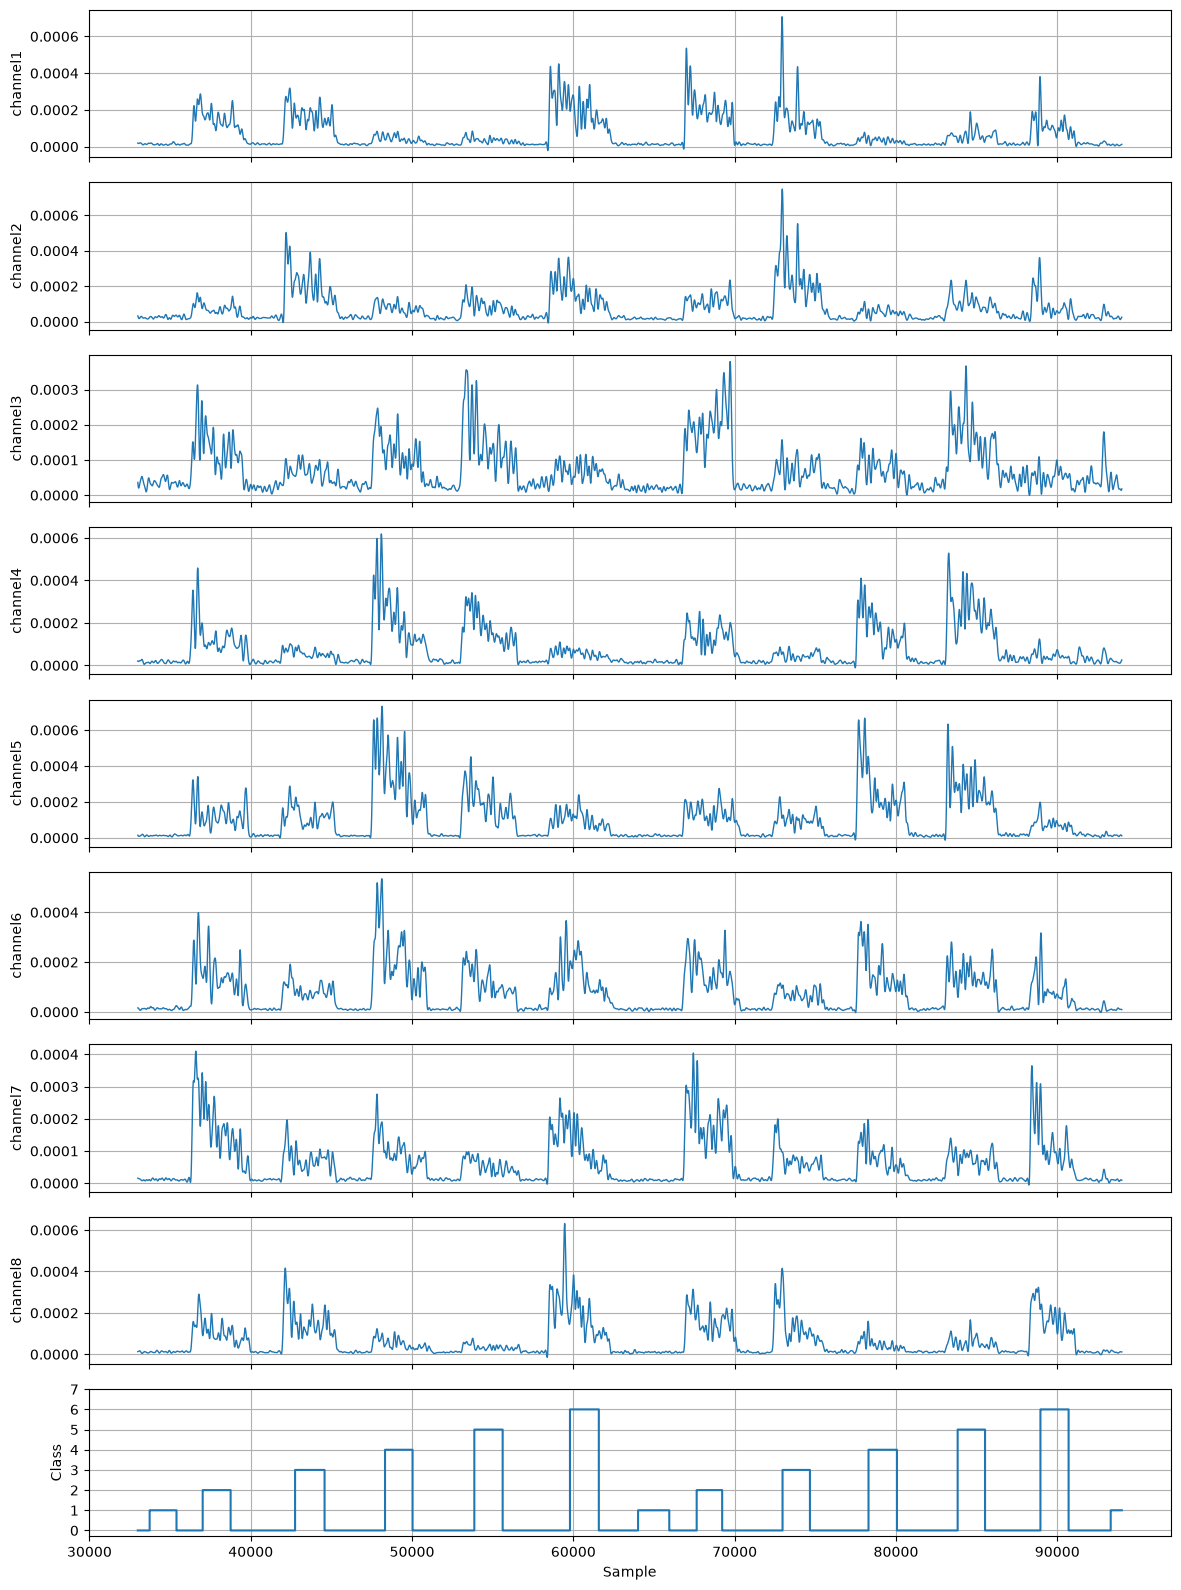

In [37]:
from scipy.signal import butter, filtfilt

channels = [f"channel{i}" for i in range(1, 9)]

start = 33000
end = 94000

# Set these parameters according to your EMG acquisition
fs = 1000          # Sampling frequency in Hz (change to your actual value)
cutoff = 5          # Envelope low-pass cutoff frequency in Hz
order = 4

# Design low-pass Butterworth filter
b, a = butter(order, cutoff / (fs / 2), btype="low")

# Calculate the envelope for each channel
envelopes = {}

for channel in channels:
    raw_emg = df[channel].to_numpy()

    # Full-wave rectification
    rectified_emg = np.abs(raw_emg)

    # Low-pass filtering to obtain the envelope
    envelopes[channel] = filtfilt(b, a, rectified_emg)

# Plot envelopes and class labels
fig, axes = plt.subplots(
    9, 1, figsize=(12, 16), sharex=True
)

for i, channel in enumerate(channels):
    axes[i].plot(
        df.index[start:end],
        envelopes[channel][start:end],
        linewidth=1
    )
    axes[i].set_ylabel(channel)
    axes[i].grid(True)

axes[8].step(
    df.index[start:end],
    df["class"].iloc[start:end],
    where="post"
)
axes[8].set_ylabel("Class")
axes[8].set_xlabel("Sample")
axes[8].set_yticks(range(8))
axes[8].grid(True)

plt.tight_layout()
plt.show()

In [38]:
# Create an empty DataFrame
features_df = pd.DataFrame()

# Loop through every stroke
for i, stroke in enumerate(strokes):

    # Rectify the EMG signal
    rectified = np.abs(stroke)

    # Calculate features for each of the 8 channels
    mav = np.mean(rectified, axis=0)
    rms = np.sqrt(np.mean(rectified**2, axis=0))

    # Normalized envelope (relative activation per channel)
    total_envelope = np.sum(mav)
    normalized_envelope = mav / (total_envelope + 1e-10)

    # Log total envelope (overall activation)
    log_total_envelope = np.log(total_envelope + 1e-10)

    # Store features in a dictionary
    features = {}

    for ch in range(8):
        features[f"MAV_ch{ch+1}"] = mav[ch]
        features[f"RMS_ch{ch+1}"] = rms[ch]
        features[f"NE_ch{ch+1}"] = normalized_envelope[ch]

    # Store log total envelope (1 feature per stroke)
    features["Log_Total_Envelope"] = log_total_envelope

    # Add corresponding label and class
    features["label"] = labels_classes[0, i]
    features["class"] = labels_classes[1, i]

    # Add stroke features as a new row
    features_df = pd.concat(
        [features_df, pd.DataFrame([features])],
        ignore_index=True
    )

# Display results
print(features_df.shape)
display(features_df)

(1812, 27)


,MAV_ch1,RMS_ch1,NE_ch1,MAV_ch2,RMS_ch2,NE_ch2,MAV_ch3,RMS_ch3,NE_ch3,MAV_ch4,...,NE_ch6,MAV_ch7,RMS_ch7,NE_ch7,MAV_ch8,RMS_ch8,NE_ch8,Log_Total_Envelope,label,class
0,0.000011,0.000015,0.101245,0.000018,0.000025,0.163025,0.000020,0.000027,0.183032,0.000016,...,0.103711,0.000011,0.000014,0.098857,0.000011,0.000014,0.097565,-9.099841,1,0
1,0.000012,0.000016,0.105984,0.000019,0.000025,0.167163,0.000022,0.000028,0.192148,0.000016,...,0.095276,0.000010,0.000014,0.092295,0.000011,0.000014,0.097250,-9.091664,1,1
2,0.000115,0.000202,0.118001,0.000068,0.000107,0.070158,0.000093,0.000144,0.095802,0.000088,...,0.170856,0.000191,0.000330,0.196887,0.000145,0.000258,0.149116,-6.937521,1,0
3,0.000194,0.000254,0.156068,0.000108,0.000138,0.087375,0.000177,0.000221,0.142284,0.000134,...,0.135333,0.000200,0.000255,0.161402,0.000132,0.000172,0.106422,-6.691471,1,2
4,0.000105,0.000212,0.132077,0.000099,0.000216,0.124365,0.000089,0.000189,0.111957,0.000080,...,0.119529,0.000101,0.000199,0.127282,0.000126,0.000227,0.158032,-7.136804,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1807,0.000031,0.000055,0.081491,0.000036,0.000057,0.095185,0.000036,0.000051,0.095106,0.000064,...,0.111833,0.000022,0.000030,0.058359,0.000019,0.000025,0.049323,-7.873572,36,0
1808,0.000080,0.000109,0.125926,0.000085,0.000109,0.133931,0.000061,0.000082,0.095228,0.000121,...,0.084709,0.000028,0.000038,0.044138,0.000024,0.000032,0.037129,-7.357005,36,5
1809,0.000034,0.000055,0.085206,0.000032,0.000048,0.080769,0.000033,0.000048,0.083256,0.000056,...,0.166583,0.000031,0.000054,0.079212,0.000038,0.000076,0.095826,-7.833874,36,0
1810,0.000046,0.000079,0.093904,0.000022,0.000028,0.044758,0.000022,0.000028,0.043735,0.000037,...,0.256187,0.000064,0.000080,0.129485,0.000068,0.000085,0.138493,-7.613635,36,6


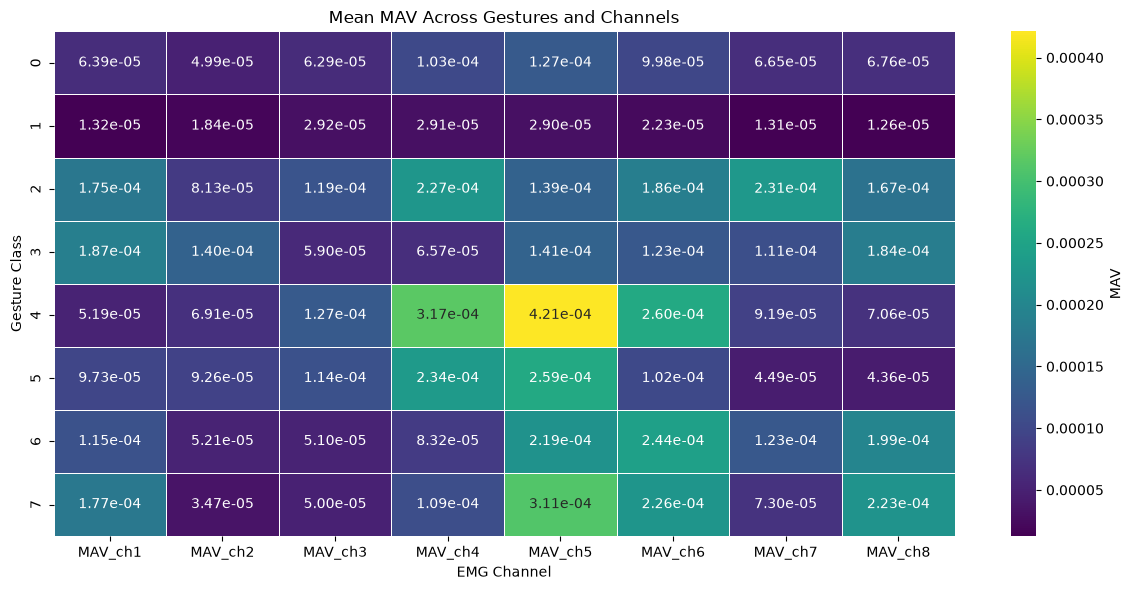

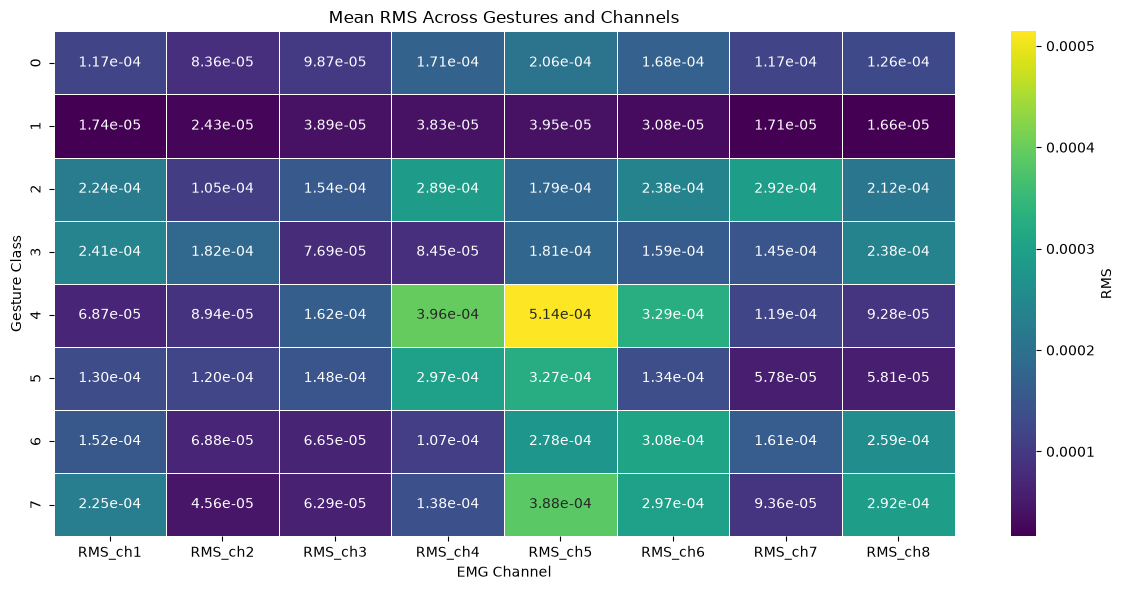

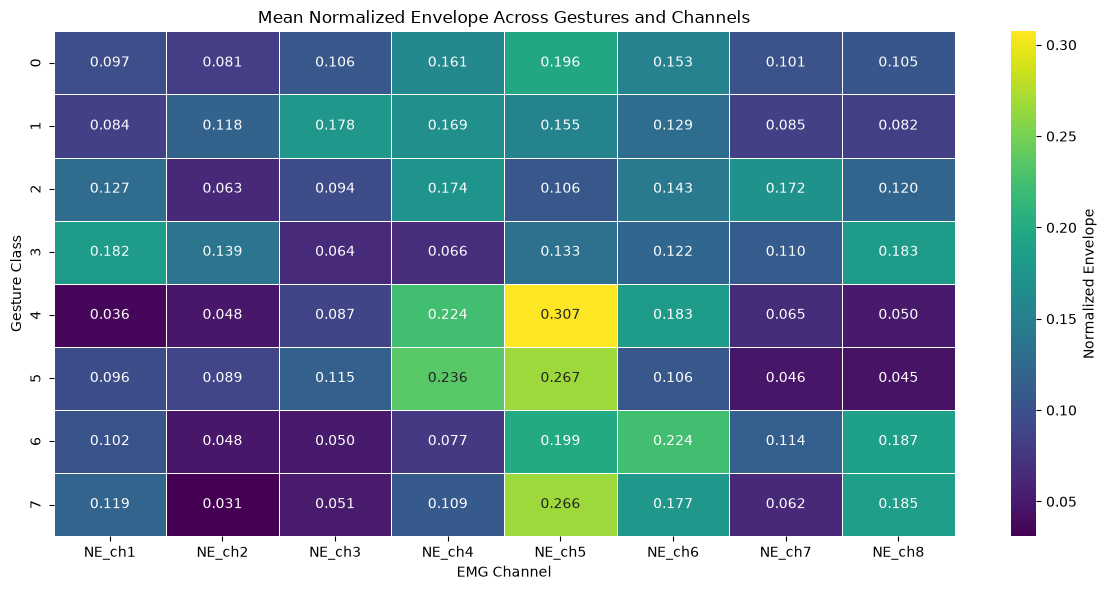

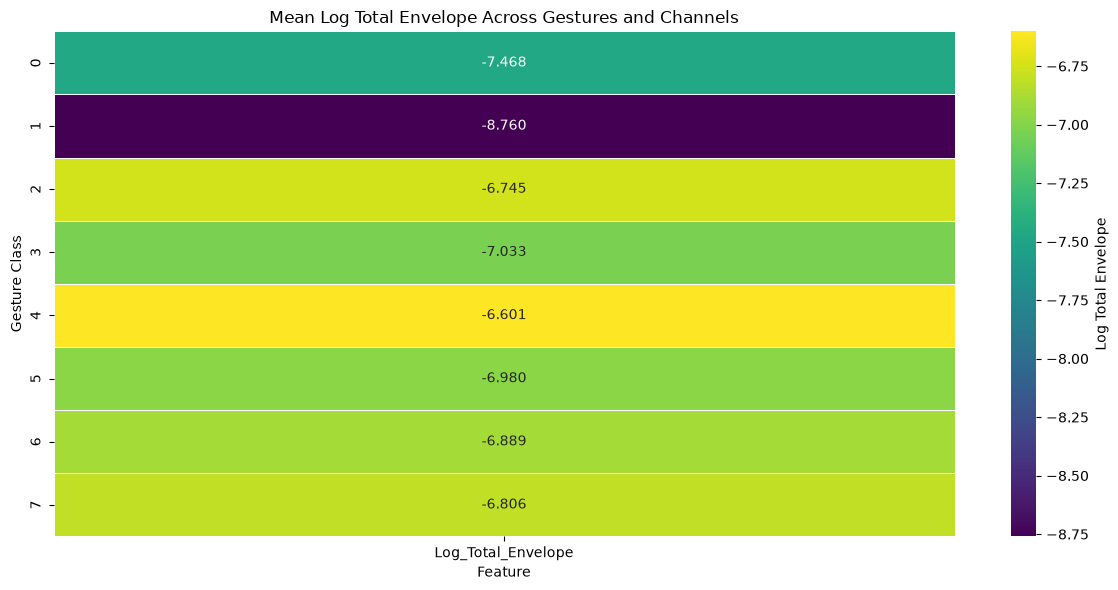

In [39]:
# Features to visualize
feature_groups = {
    "MAV": [f"MAV_ch{i}" for i in range(1, 9)],
    "RMS": [f"RMS_ch{i}" for i in range(1, 9)],
    "Normalized Envelope": [f"NE_ch{i}" for i in range(1, 9)],
    "Log Total Envelope": ["Log_Total_Envelope"]
}

# Loop through each feature group
for feature_name, columns in feature_groups.items():

    # Calculate mean feature values for each gesture class
    mean_features = features_df.groupby("class")[columns].mean()

    # Create a separate figure for each feature
    plt.figure(figsize=(12, 6))

    sns.heatmap(
        mean_features,
        annot=True,
        fmt=".2e" if feature_name in ["MAV", "RMS"] else ".3f",
        cmap="viridis",
        linewidths=0.5,
        cbar_kws={"label": feature_name}
    )

    plt.title(f"Mean {feature_name} Across Gestures and Channels")
    plt.xlabel("EMG Channel" if feature_name != "Log Total Envelope" else "Feature")
    plt.ylabel("Gesture Class")

    plt.tight_layout()
    plt.show()

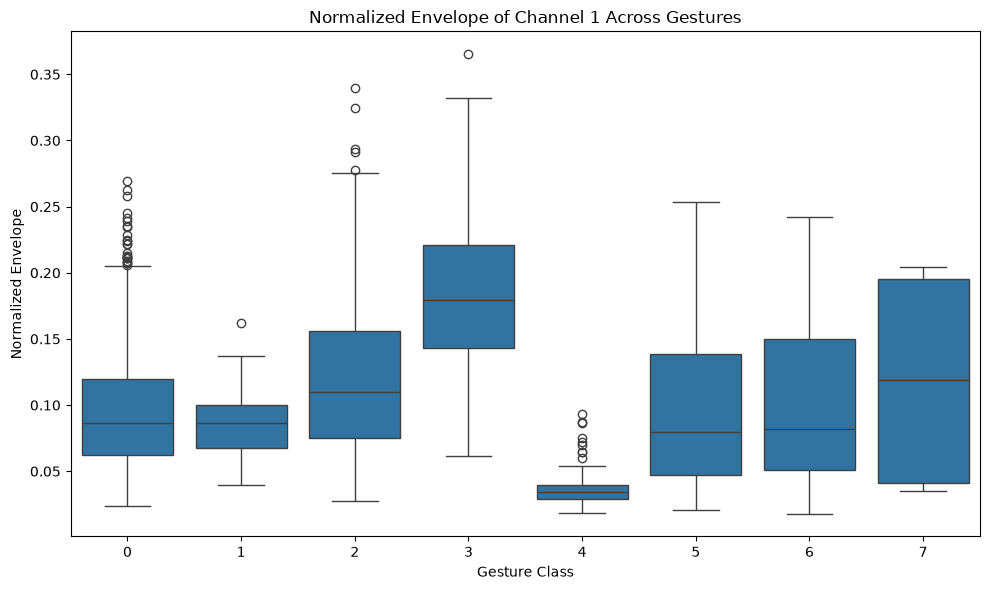

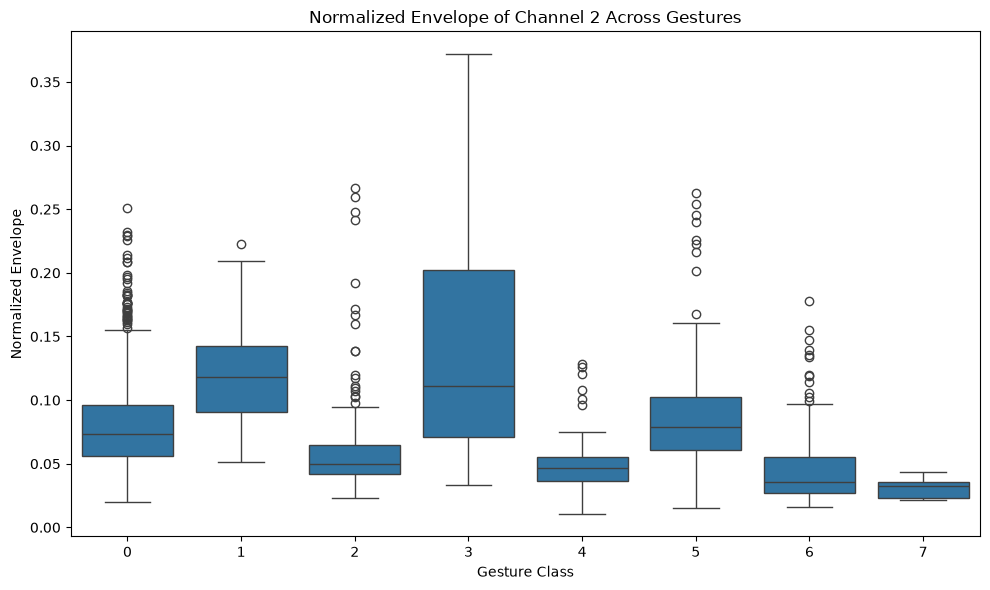

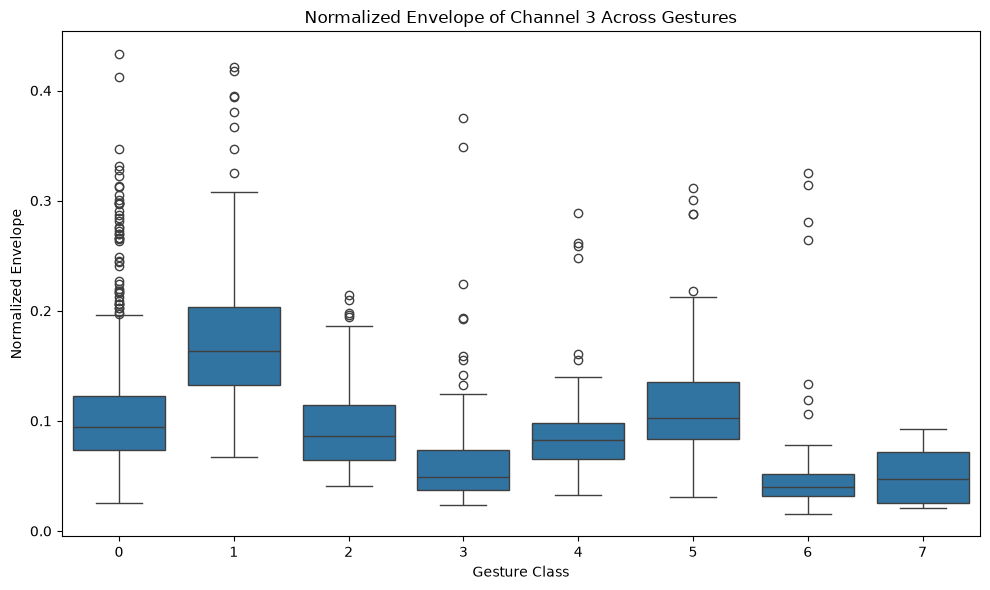

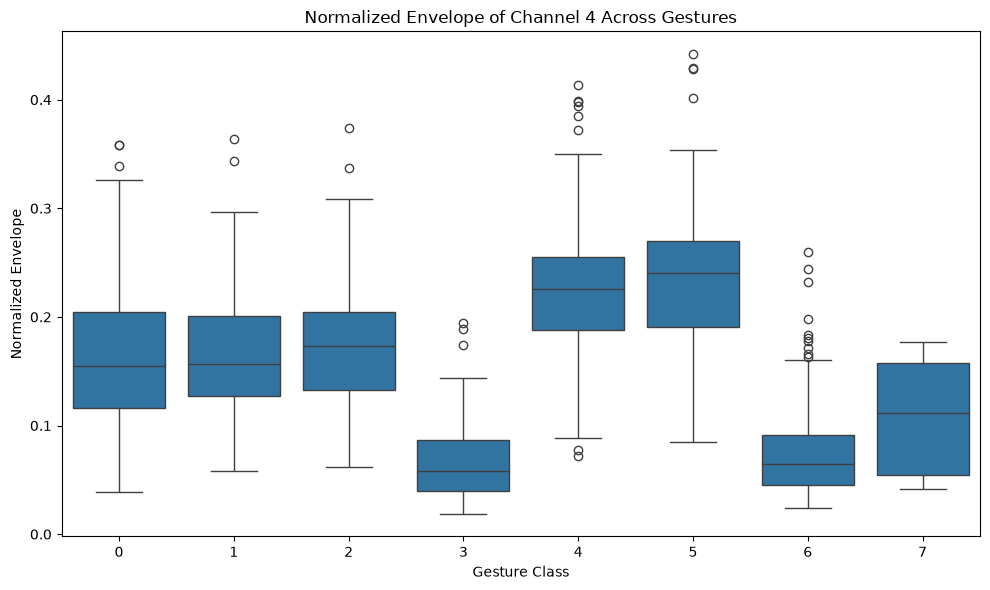

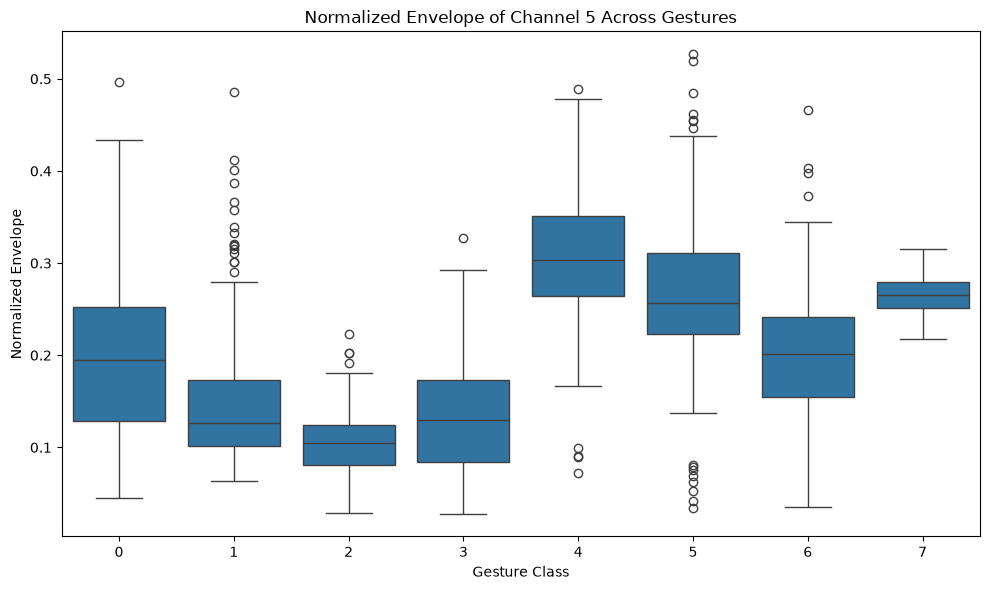

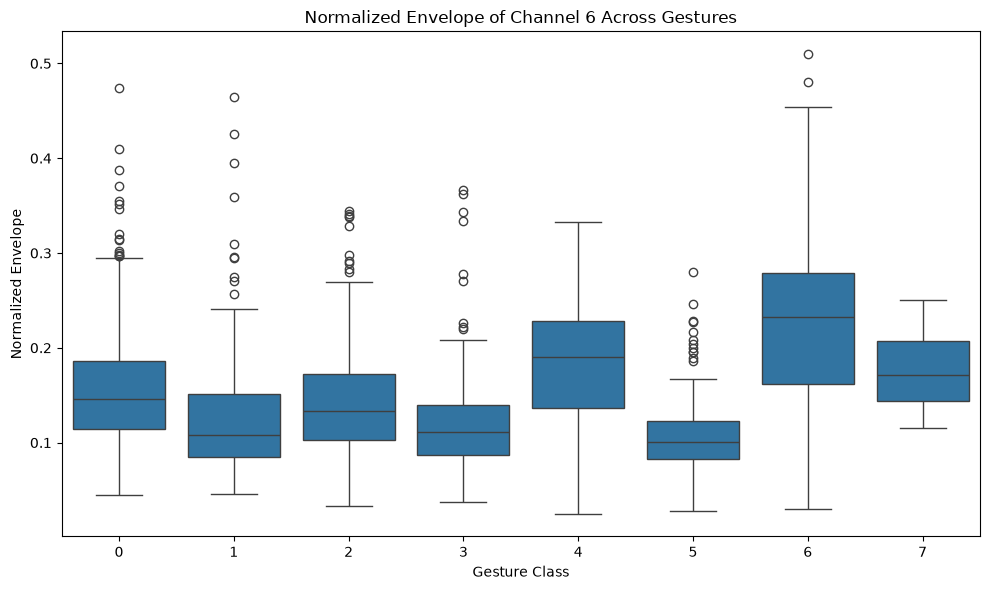

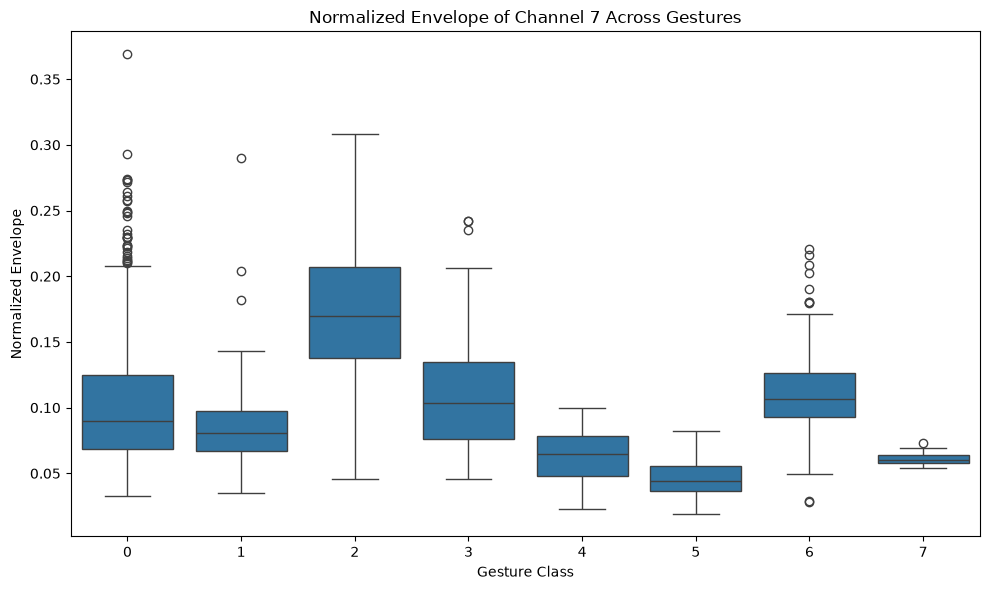

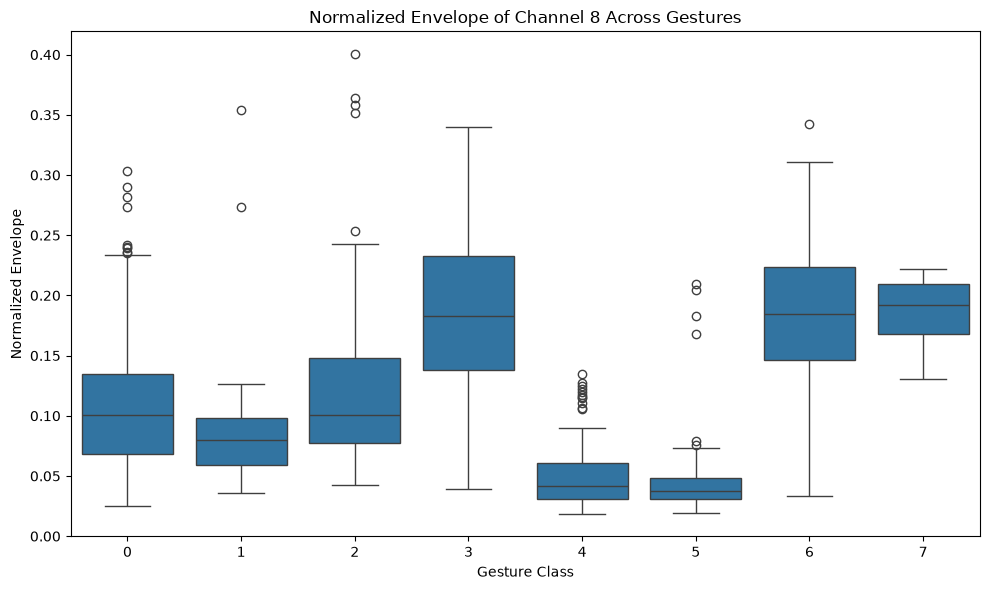

In [41]:
for ch in range(1, 9):

    plt.figure(figsize=(10, 6))

    sns.boxplot(
        data=features_df,
        x="class",
        y=f"NE_ch{ch}"
    )

    plt.title(f"Normalized Envelope of Channel {ch} Across Gestures")
    plt.xlabel("Gesture Class")
    plt.ylabel("Normalized Envelope")

    plt.tight_layout()
    plt.show()

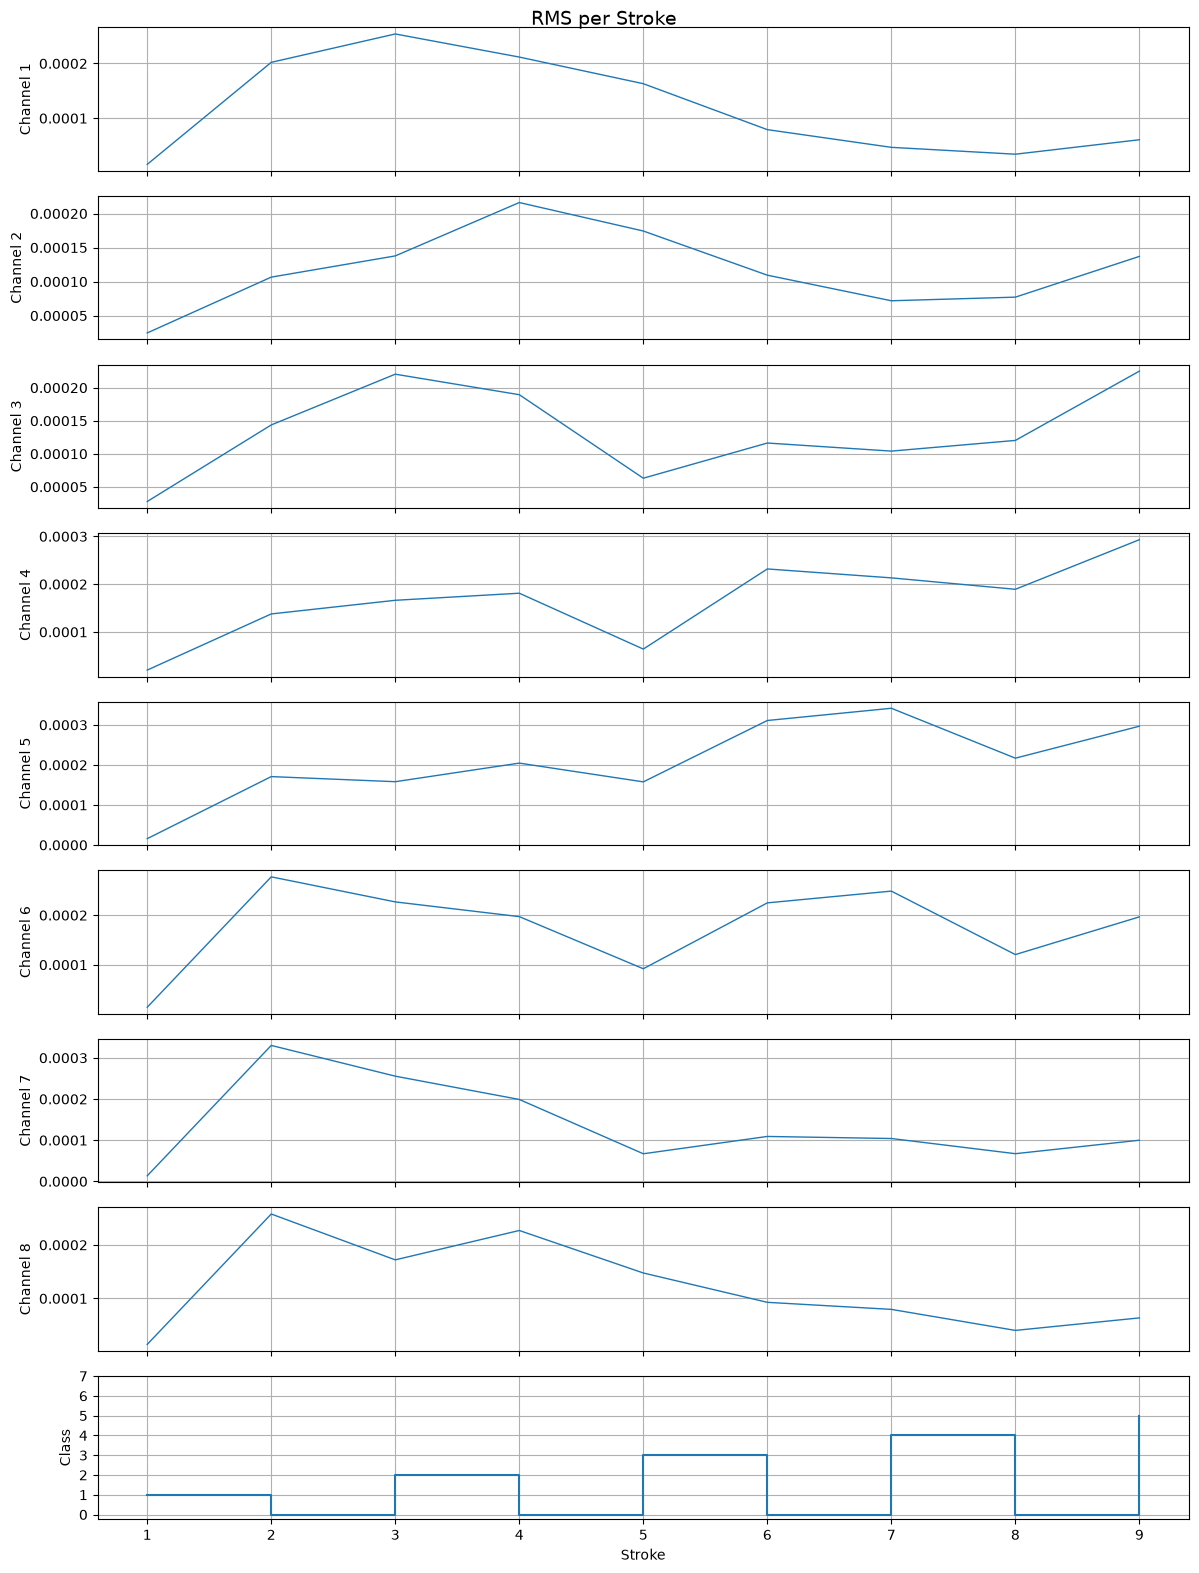

In [9]:
###

start_stroke = 1
end_stroke = 10

# Select strokes within the specified range
plot_df = features_df.iloc[start_stroke:end_stroke]

# Keep original stroke numbers
stroke_numbers = np.arange(start_stroke, start_stroke + len(plot_df))

###

fig, axes = plt.subplots(9, 1, figsize=(12, 16), sharex=True)

for ch in range(8):
    axes[ch].plot(
        stroke_numbers,
        plot_df[f"RMS_ch{ch+1}"],
        linewidth=1
    )
    axes[ch].set_ylabel(f"Channel {ch+1}")
    axes[ch].grid(True)

axes[8].step(
    stroke_numbers,
    plot_df["class"],
    where="post"
)
axes[8].set_ylabel("Class")
axes[8].set_xlabel("Stroke")
axes[8].set_yticks(sorted(features_df["class"].unique()))
axes[8].grid(True)

fig.suptitle("RMS per Stroke", fontsize=14)
plt.tight_layout()
plt.show()


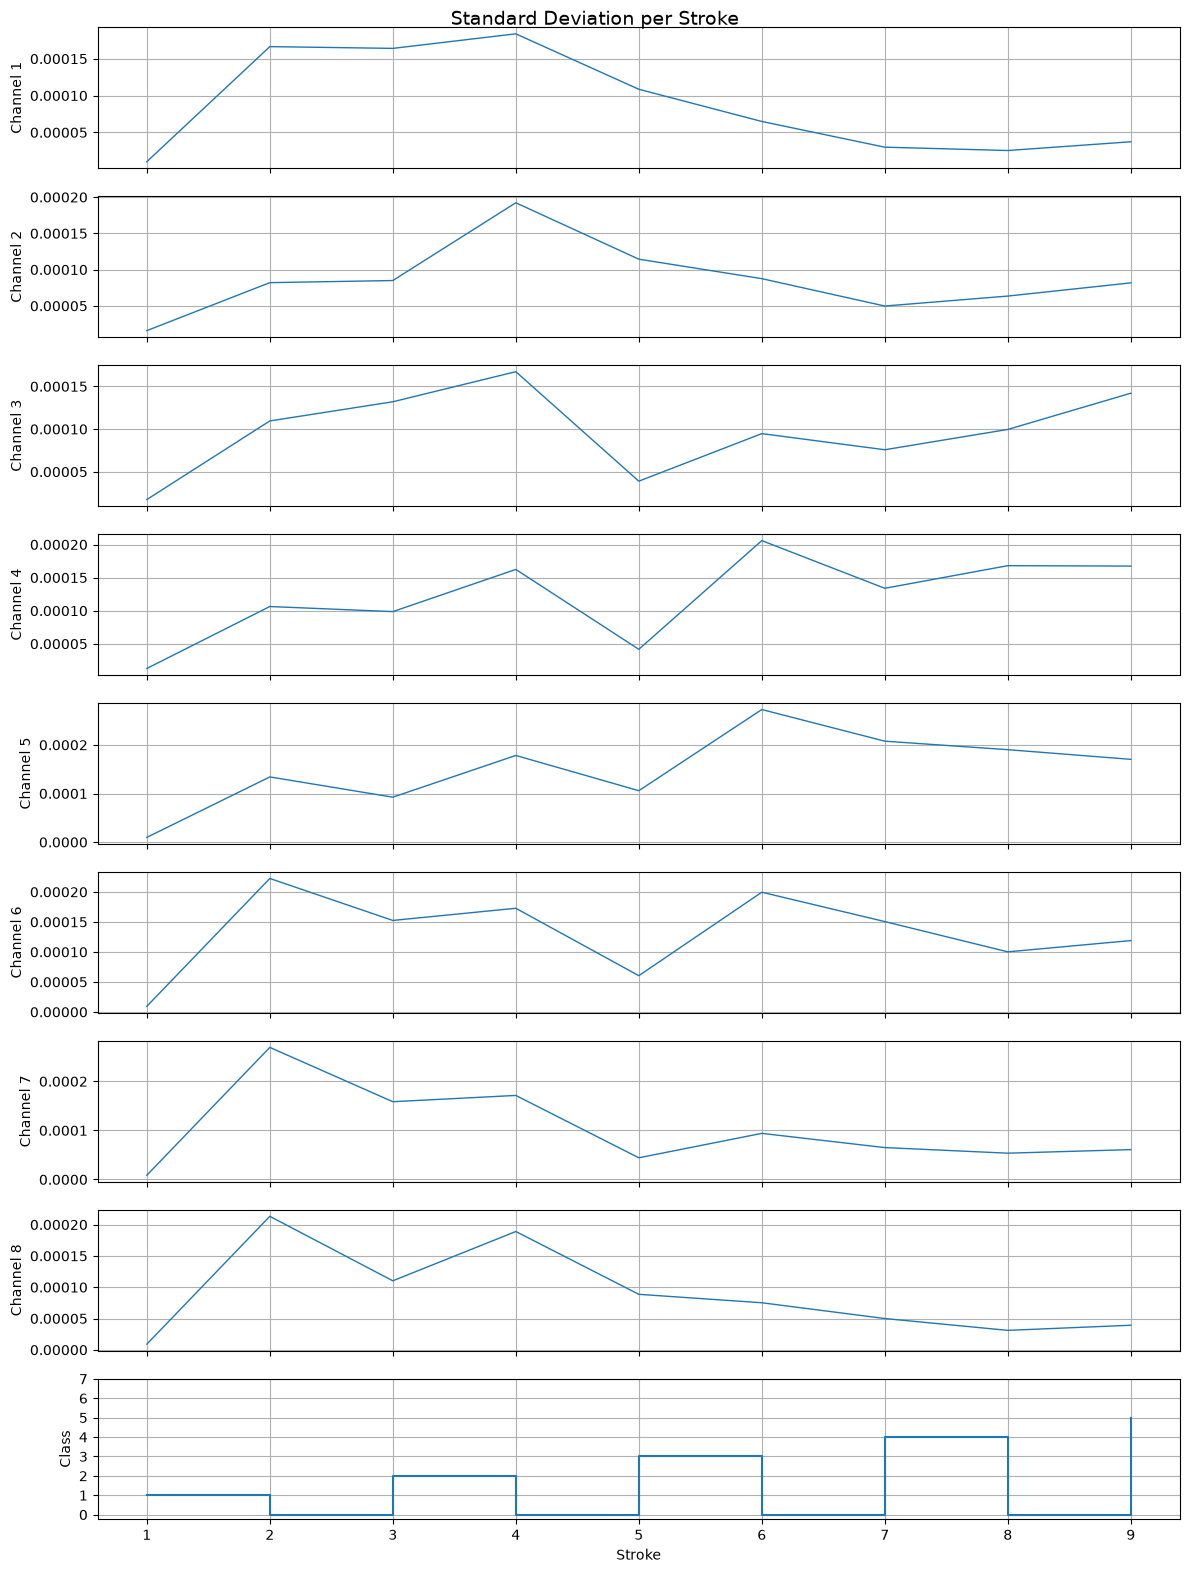

In [12]:
# STDEV
fig, axes = plt.subplots(9, 1, figsize=(12, 16), sharex=True)

for ch in range(8):
    axes[ch].plot(
        stroke_numbers,
        plot_df[f"STD_ch{ch+1}"],
        linewidth=1
    )
    axes[ch].set_ylabel(f"Channel {ch+1}")
    axes[ch].grid(True)

axes[8].step(
    stroke_numbers,
    plot_df["class"],
    where="post"
)
axes[8].set_ylabel("Class")
axes[8].set_xlabel("Stroke")
axes[8].set_yticks(sorted(features_df["class"].unique()))
axes[8].grid(True)

fig.suptitle("Standard Deviation per Stroke", fontsize=14)
plt.tight_layout()
plt.show()


In [17]:
print(features_df.columns.tolist())
print(features_df.shape)

['RMS_ch1', 'STD_ch1', 'VAR_ch1', 'MAX_ch1', 'RMS_ch2', 'STD_ch2', 'VAR_ch2', 'MAX_ch2', 'RMS_ch3', 'STD_ch3', 'VAR_ch3', 'MAX_ch3', 'RMS_ch4', 'STD_ch4', 'VAR_ch4', 'MAX_ch4', 'RMS_ch5', 'STD_ch5', 'VAR_ch5', 'MAX_ch5', 'RMS_ch6', 'STD_ch6', 'VAR_ch6', 'MAX_ch6', 'RMS_ch7', 'STD_ch7', 'VAR_ch7', 'MAX_ch7', 'RMS_ch8', 'STD_ch8', 'VAR_ch8', 'MAX_ch8', 'label', 'class']
(1812, 34)


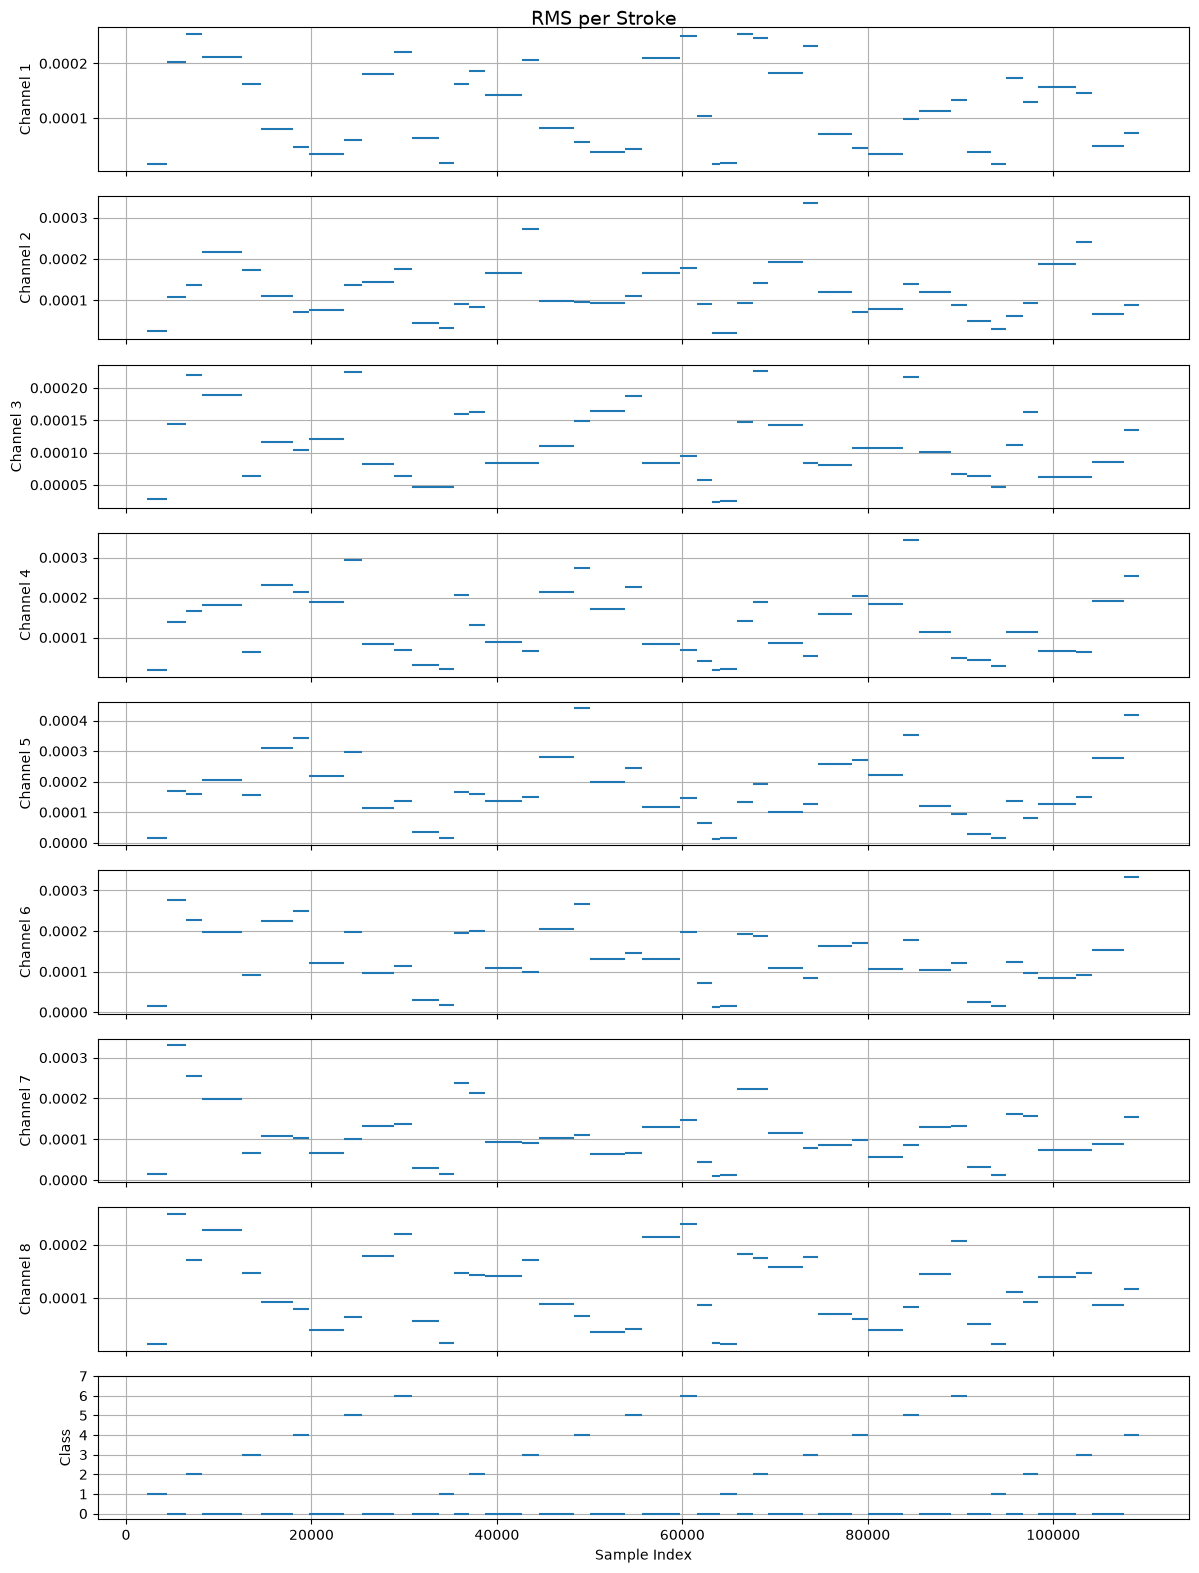

In [ ]:

# Select stroke range
start_stroke = 1
end_stroke = 45

# Use the same groups that were used to create strokes
groups = list(data.groupby("gesture_block", sort=False))

assert len(groups) == len(features_df), "Groups and features do not match!"

# Create figure
fig, axes = plt.subplots(9, 1, figsize=(12, 16), sharex=True)

for i in range(start_stroke, min(end_stroke, len(groups))):

    # Get original sample indices for this stroke
    _, group = groups[i]

    start_idx = group.index[0]
    end_idx = group.index[-1] + 1

    # Plot RMS for each channel
    for ch in range(8):

        rms = features_df.iloc[i][f"RMS_ch{ch+1}"]

        axes[ch].hlines(
            rms,
            start_idx,
            end_idx,
            linewidth=1.5
        )

    # Plot corresponding class
    axes[8].hlines(
        features_df.iloc[i]["class"],
        start_idx,
        end_idx,
        linewidth=1.5
    )

# Format channel plots
for ch in range(8):
    axes[ch].set_ylabel(f"Channel {ch+1}")
    axes[ch].grid(True)

# Format class plot
axes[8].set_ylabel("Class")
axes[8].set_xlabel("Sample Index")
axes[8].set_yticks(sorted(features_df["class"].unique()))
axes[8].grid(True)

fig.suptitle("RMS per Stroke", fontsize=14)

plt.tight_layout()
plt.show()


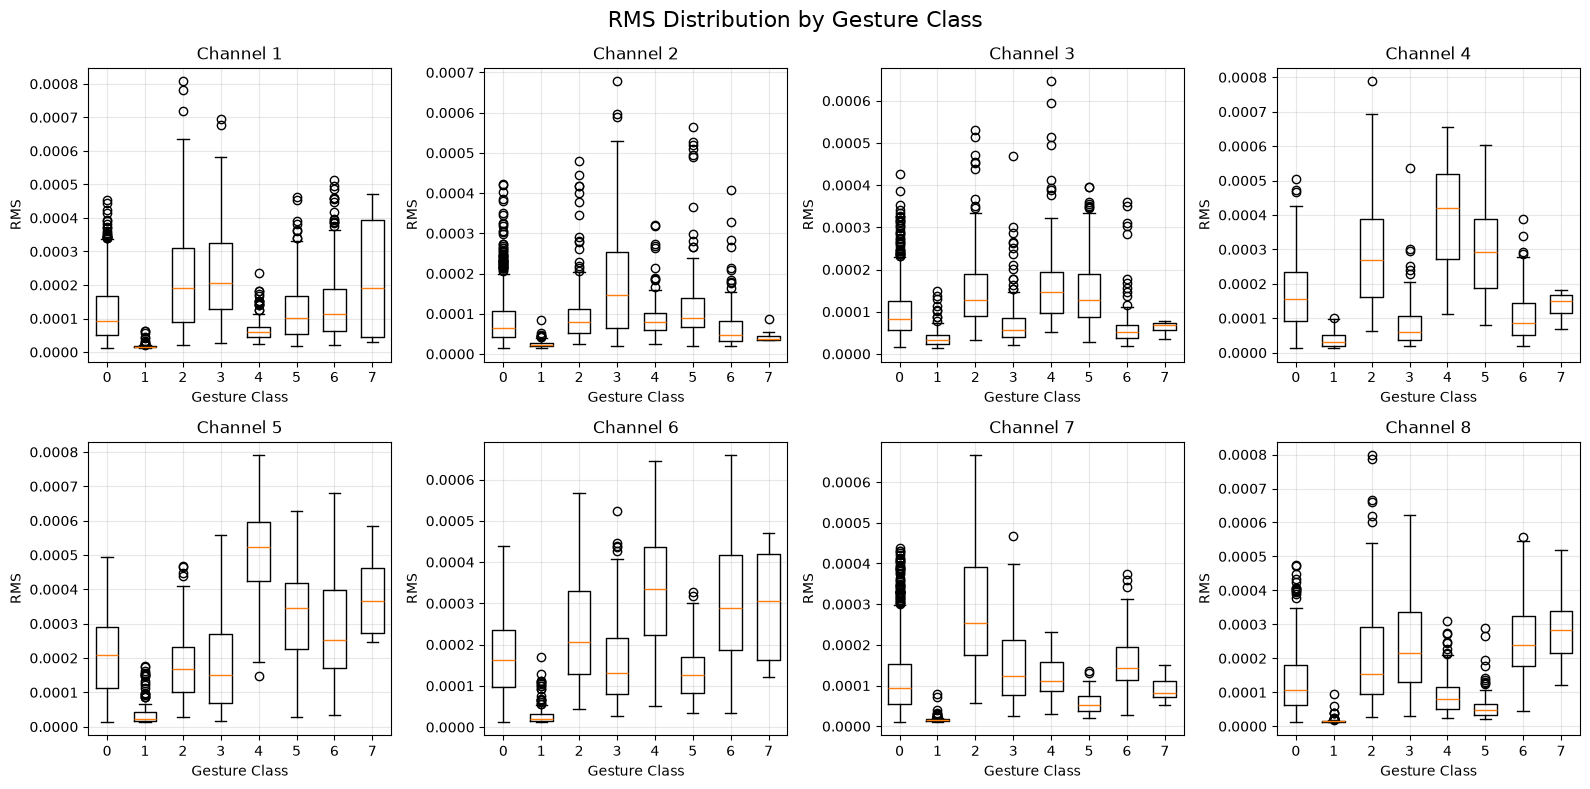

In [ ]:
# Boxplot of all RMS values for each channel, grouped by gesture class
# Get all gesture classes
classes = sorted(features_df["class"].unique())

# Create 2x4 subplots
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ch in range(8):

    column = f"RMS_ch{ch+1}"

    # Collect RMS values for each class
    rms_by_class = [
        features_df.loc[
            features_df["class"] == c, column
        ].dropna().values
        for c in classes
    ]

    # Create boxplot
    axes[ch].boxplot(
        rms_by_class,
        positions=classes,
        widths=0.6
    )

    axes[ch].set_title(f"Channel {ch+1}")
    axes[ch].set_xlabel("Gesture Class")
    axes[ch].set_ylabel("RMS")
    axes[ch].set_xticks(classes)
    axes[ch].grid(True, alpha=0.3)

fig.suptitle("RMS Distribution by Gesture Class", fontsize=16)

plt.tight_layout()
plt.show()


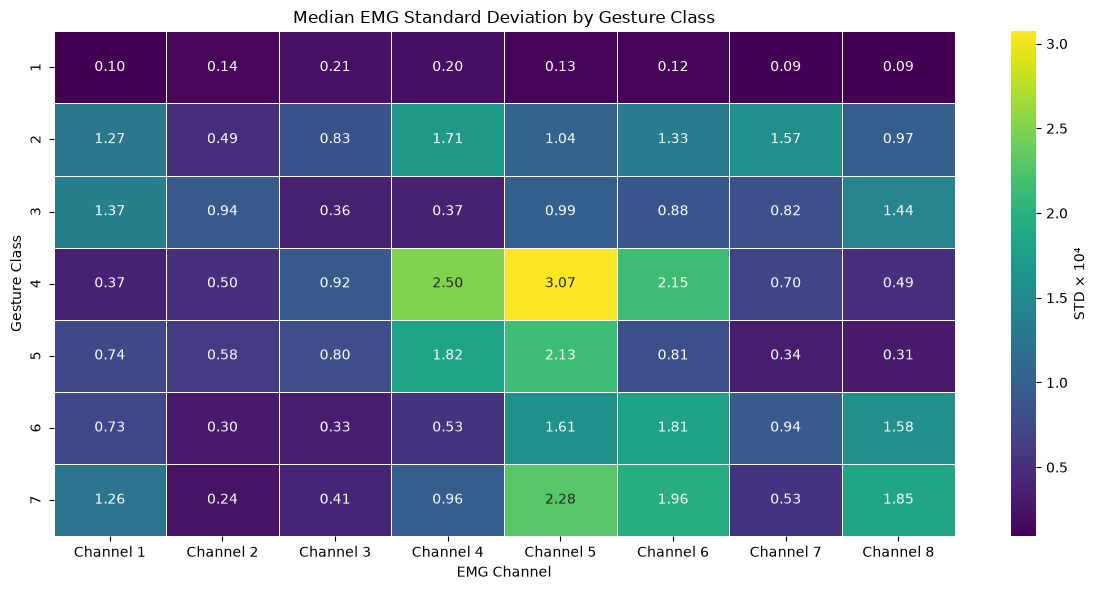

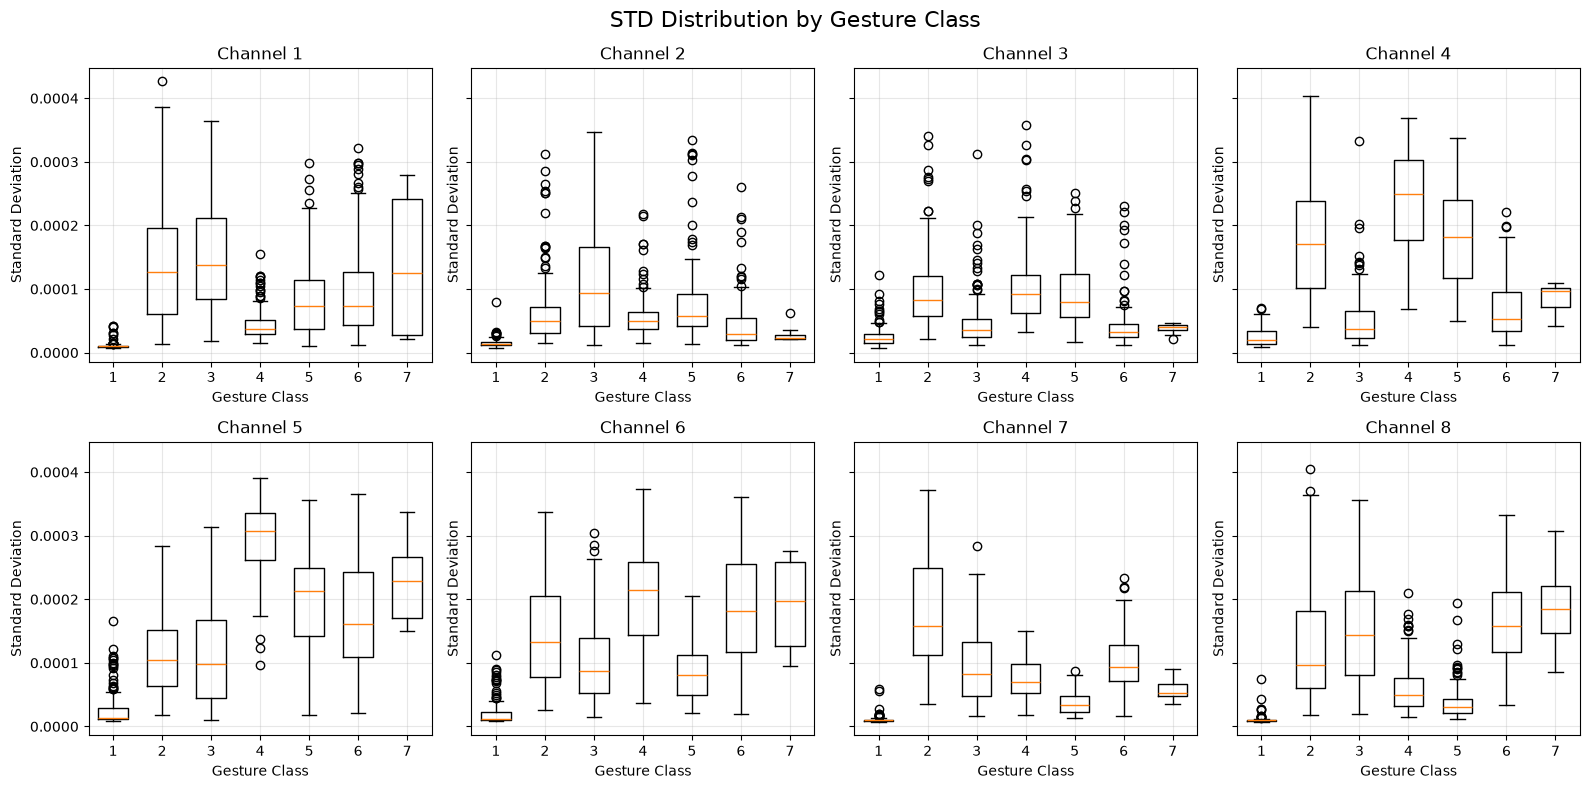

In [31]:
# Heatmap of median STD values for each class and channel
# Exclude class 0 (rest)
filtered_df = features_df[features_df["class"] != 0]

# Select STD features
std_columns = [f"STD_ch{i}" for i in range(1, 9)]

# Calculate median STD for each class and channel
std_matrix = filtered_df.groupby("class")[std_columns].median()

# Rename columns for readability
std_matrix.columns = [f"Channel {i}" for i in range(1, 9)]

# Scale values for readability
std_matrix = std_matrix * 1e4

# Plot heatmap
plt.figure(figsize=(12, 6))

sns.heatmap(
    std_matrix,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    linewidths=0.5,
    cbar_kws={"label": "STD × 10⁴"}
)

plt.title("Median EMG Standard Deviation by Gesture Class")
plt.xlabel("EMG Channel")
plt.ylabel("Gesture Class")

plt.tight_layout()
plt.show()

# Boxplot of all STD values for each channel, grouped by gesture class

# Exclude class 0
filtered_df = features_df[features_df["class"] != 0]

classes = sorted(filtered_df["class"].unique())

fig, axes = plt.subplots(
    2, 4, figsize=(16, 8), sharey=True
)

axes = axes.flatten()

for ch in range(8):

    column = f"STD_ch{ch+1}"

    std_by_class = [
        filtered_df.loc[
            filtered_df["class"] == c, column
        ].dropna().values
        for c in classes
    ]

    axes[ch].boxplot(
        std_by_class,
        positions=classes,
        widths=0.6
    )

    axes[ch].set_title(f"Channel {ch+1}")
    axes[ch].set_xlabel("Gesture Class")
    axes[ch].set_ylabel("Standard Deviation")
    axes[ch].set_xticks(classes)
    axes[ch].grid(True, alpha=0.3)

fig.suptitle(
    "STD Distribution by Gesture Class",
    fontsize=16
)

plt.tight_layout()
plt.show()


,CAR_ch1,CAR_ch2,CAR_ch3,CAR_ch4,CAR_ch5,CAR_ch6,CAR_ch7,CAR_ch8,class
0,0.101292,0.171893,0.183392,0.148567,0.104584,0.098160,0.096328,0.095784,0
1,0.107703,0.168406,0.190398,0.138107,0.108196,0.097457,0.092539,0.097195,1
2,0.124253,0.065545,0.088356,0.084683,0.105054,0.170614,0.203005,0.158490,0
3,0.159585,0.086590,0.138601,0.104502,0.099373,0.142605,0.160588,0.108157,2
4,0.130200,0.132949,0.116520,0.111367,0.125779,0.121266,0.122350,0.139569,0


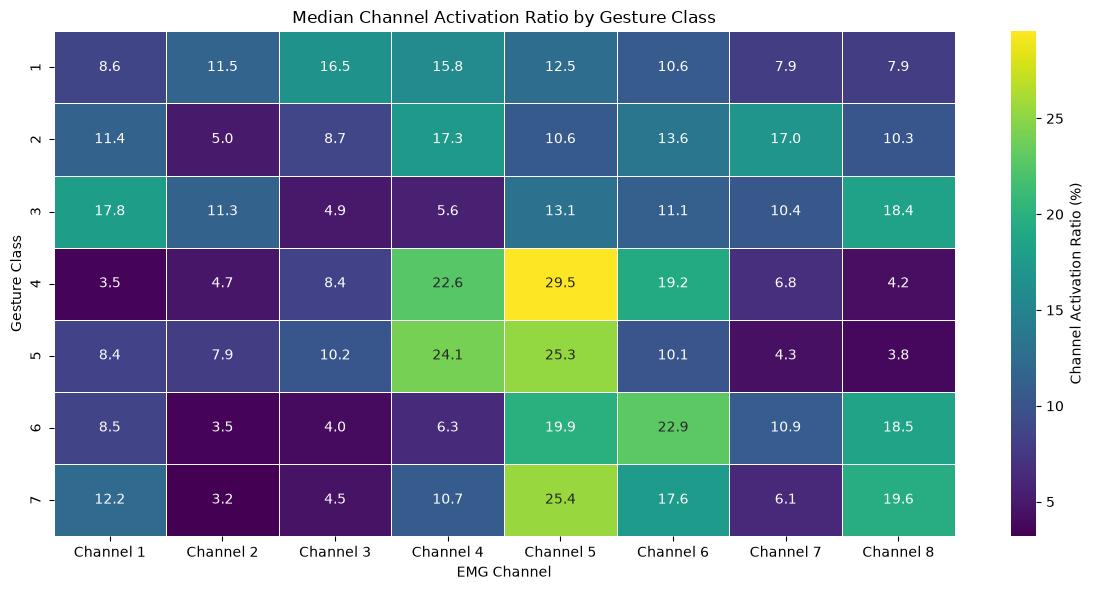

In [33]:
# Select RMS columns
rms_columns = [f"RMS_ch{i}" for i in range(1, 9)]

# Extract RMS values
rms_values = features_df[rms_columns].to_numpy(dtype=float)

# Calculate total RMS across all channels for each stroke
total_rms = np.sum(rms_values, axis=1, keepdims=True)

# Calculate channel activation ratios
activation_ratios = np.divide(
    rms_values,
    total_rms,
    out=np.full_like(rms_values, np.nan),
    where=total_rms > 1e-12
)

# Add features to existing DataFrame
for ch in range(8):
    features_df[f"CAR_ch{ch+1}"] = activation_ratios[:, ch]

# Display results
car_columns = [f"CAR_ch{i}" for i in range(1, 9)]

display(features_df[car_columns + ["class"]].head())



# Exclude resting class
filtered_df = features_df[features_df["class"] != 0]

# Select activation ratio columns
car_columns = [f"CAR_ch{i}" for i in range(1, 9)]

# Calculate median activation ratio per class
car_matrix = filtered_df.groupby("class")[car_columns].median()

# Convert ratios to percentages
car_matrix = car_matrix * 100

# Rename columns
car_matrix.columns = [f"Channel {i}" for i in range(1, 9)]

# Plot heatmap
plt.figure(figsize=(12, 6))

sns.heatmap(
    car_matrix,
    annot=True,
    fmt=".1f",
    cmap="viridis",
    linewidths=0.5,
    cbar_kws={"label": "Channel Activation Ratio (%)"}
)

plt.title("Median Channel Activation Ratio by Gesture Class")
plt.xlabel("EMG Channel")
plt.ylabel("Gesture Class")

plt.tight_layout()
plt.show()
